In [529]:
import urllib.request
from pathlib import Path

Path("data").mkdir(exist_ok=True)

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

urllib.request.urlretrieve(url, "data/Telco-Customer-Churn.csv")

print("Download complete!")

Download complete!


In [530]:
import pandas as pd

In [531]:
df = pd.read_csv("data/Telco-Customer-Churn.csv")

In [532]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [533]:
print("Dataset shape:", df.shape)

Dataset shape: (7043, 21)


In [534]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [535]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [536]:
df["Churn"].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [537]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [538]:
df["TotalCharges"].isnull().sum()

11

In [539]:
df = df.dropna(subset=["TotalCharges"])

In [540]:
print("Dataset shape:", df.shape)
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

Dataset shape: (7032, 21)
Missing TotalCharges: 0


In [541]:
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7032, 19)
Target shape: (7032,)


In [542]:
X.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65


In [543]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (5625, 19)
X_test shape: (1407, 19)
y_train shape: (5625,)
y_test shape: (1407,)


In [544]:
numerical_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_columns = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical columns:", numerical_columns)
print("Number of numerical columns:", len(numerical_columns))

print("\nCategorical columns:", categorical_columns)
print("Number of categorical columns:", len(categorical_columns))

Numerical columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Number of numerical columns: 4

Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Number of categorical columns: 15


In [545]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_columns),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [546]:
knn_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

print("KNN pipeline created successfully!")

KNN pipeline created successfully!


In [547]:
knn_model.fit(X_train, y_train)

print("KNN model trained successfully!")

KNN model trained successfully!


In [548]:
y_pred = knn_model.predict(X_test)

print("Predictions completed successfully!")
print("First 10 predictions:", y_pred[:10])

Predictions completed successfully!
First 10 predictions: ['No' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes' 'No']


In [549]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Accuracy: {accuracy * 100:.2f}%")

Test Accuracy: 0.7612
Test Accuracy: 76.12%


In [550]:
from sklearn.metrics import confusion_matrix, classification_report

cm = confusion_matrix(y_test, y_pred, labels=["No", "Yes"])

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, labels=["No", "Yes"]))

Confusion Matrix:
[[854 179]
 [157 217]]

Classification Report:
              precision    recall  f1-score   support

          No       0.84      0.83      0.84      1033
         Yes       0.55      0.58      0.56       374

    accuracy                           0.76      1407
   macro avg       0.70      0.70      0.70      1407
weighted avg       0.77      0.76      0.76      1407



In [551]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {
    "classifier__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "classifier__weights": ["uniform", "distance"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=knn_model,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation F1-score:", round(grid_search.best_score_, 4))

Fitting 5 folds for each of 14 candidates, totalling 70 fits
Best parameters: {'classifier__n_neighbors': 3, 'classifier__weights': 'uniform'}
Best cross-validation F1-score: nan


c:\Users\Bharathi\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\model_selection\_search.py:1051: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan nan nan nan nan nan nan nan nan nan]
  warnings.warn(


In [552]:
from sklearn.metrics import f1_score, make_scorer
from sklearn.model_selection import GridSearchCV, StratifiedKFold

churn_f1 = make_scorer(f1_score, pos_label="Yes")

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=knn_model,
    param_grid=param_grid,
    scoring=churn_f1,
    cv=cv,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation F1-score:", round(grid_search.best_score_, 4))

Fitting 5 folds for each of 14 candidates, totalling 70 fits
Best parameters: {'classifier__n_neighbors': 21, 'classifier__weights': 'uniform'}
Best cross-validation F1-score: 0.5943


In [553]:
best_knn_model = grid_search.best_estimator_

y_pred_tuned = best_knn_model.predict(X_test)

print("Best parameters:", grid_search.best_params_)
print("\nTuned Model Accuracy:",
      round(accuracy_score(y_test, y_pred_tuned) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_tuned,
    labels=["No", "Yes"]
))

Best parameters: {'classifier__n_neighbors': 21, 'classifier__weights': 'uniform'}

Tuned Model Accuracy: 78.11 %

Classification Report:
              precision    recall  f1-score   support

          No       0.85      0.85      0.85      1033
         Yes       0.59      0.58      0.59       374

    accuracy                           0.78      1407
   macro avg       0.72      0.72      0.72      1407
weighted avg       0.78      0.78      0.78      1407



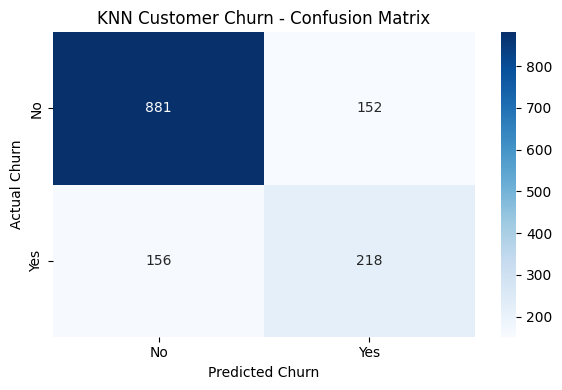

In [554]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_tuned = confusion_matrix(
    y_test,
    y_pred_tuned,
    labels=["No", "Yes"]
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_tuned,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Predicted Churn")
plt.ylabel("Actual Churn")
plt.title("KNN Customer Churn - Confusion Matrix")
plt.tight_layout()
plt.show()

In [555]:
import joblib
from pathlib import Path

Path("outputs").mkdir(exist_ok=True)

joblib.dump(best_knn_model, "outputs/knn_churn_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [556]:
import joblib

loaded_model = joblib.load("outputs/knn_churn_model.pkl")

sample_customers = X_test.iloc[:5]
sample_predictions = loaded_model.predict(sample_customers)

print("Model loaded successfully!")
print("Predictions:", sample_predictions)

Model loaded successfully!
Predictions: ['No' 'Yes' 'No' 'No' 'No']


In [557]:
plt.savefig(
    "outputs/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

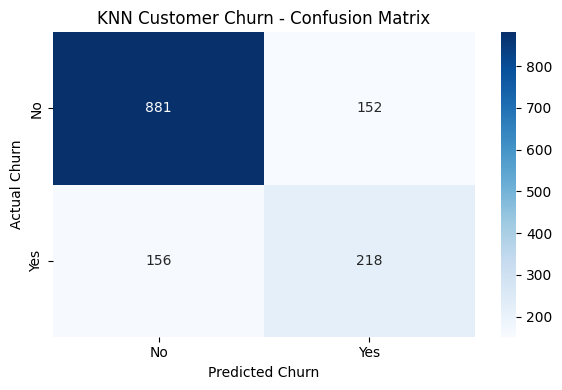

In [558]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_tuned = confusion_matrix(
    y_test,
    y_pred_tuned,
    labels=["No", "Yes"]
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_tuned,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Predicted Churn")
plt.ylabel("Actual Churn")
plt.title("KNN Customer Churn - Confusion Matrix")
plt.tight_layout()

plt.savefig(
    "outputs/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

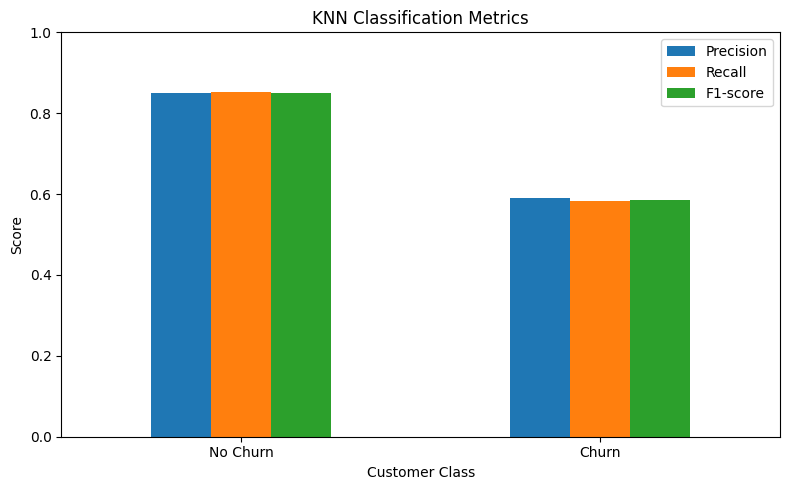

In [559]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd
import matplotlib.pyplot as plt

metrics = pd.DataFrame({
    "Precision": [
        precision_score(y_test, y_pred_tuned, pos_label="No"),
        precision_score(y_test, y_pred_tuned, pos_label="Yes")
    ],
    "Recall": [
        recall_score(y_test, y_pred_tuned, pos_label="No"),
        recall_score(y_test, y_pred_tuned, pos_label="Yes")
    ],
    "F1-score": [
        f1_score(y_test, y_pred_tuned, pos_label="No"),
        f1_score(y_test, y_pred_tuned, pos_label="Yes")
    ]
}, index=["No Churn", "Churn"])

ax = metrics.plot(kind="bar", figsize=(8, 5))

ax.set_title("KNN Classification Metrics")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.set_xlabel("Customer Class")

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "outputs/classification_metrics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

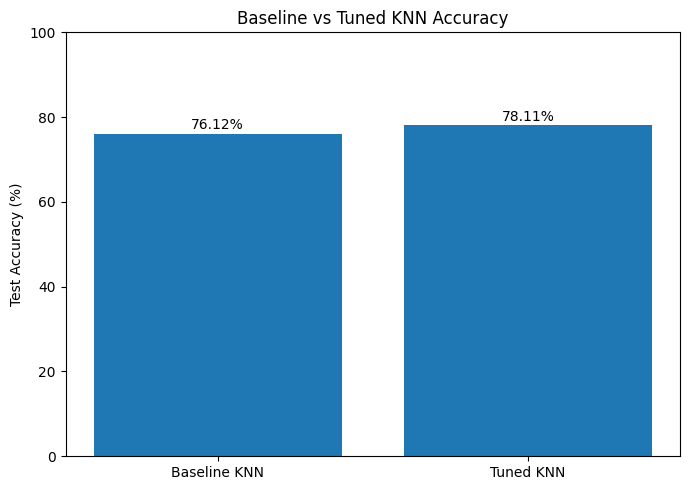

In [560]:
import matplotlib.pyplot as plt

model_names = ["Baseline KNN", "Tuned KNN"]
accuracies = [76.12, 78.11]

plt.figure(figsize=(7, 5))

bars = plt.bar(model_names, accuracies)

plt.title("Baseline vs Tuned KNN Accuracy")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f"{height:.2f}%",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    "outputs/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [561]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier